# Влияние социально-демографических характеристик на финансовое поведение

**Данные:** опрос Банка России о финансовом поведении населения, 2022 г. (`data/central_bank_survey_2022.sav`), 12 162 респондента.

**Задача:** оценить влияние на финансовое поведение:
1. возраста;
2. уровня образования;
3. особенностей места проживания;
4. социального положения.

**Методы:** таблицы сопряжённости, критерий хи-квадрат, V Крамера, коэффициенты корреляции Пирсона, Спирмена, Кендалла, точечно-бисериальный. Уровень значимости α = 0,05.

In [14]:
import sys; print(sys.executable)

/Users/arkadijsidlovskij/Yandex.Disk.localized/Аркадий/Свое/quant-analysis-social/venv/bin/python


In [15]:
import pandas as pd
import numpy as np
import pyreadstat as prs
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pearsonr, spearmanr, kendalltau, pointbiserialr
from scipy.stats.contingency import association
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)

## 1. Импорт библиотек

## 2. Загрузка данных

In [16]:
# читаем файл SPSS вместе с метками вопросов и ответов
df, meta = prs.read_sav('data/central_bank_survey_2022.sav')
print('Строк (респондентов):', df.shape[0], '| столбцов (переменных):', df.shape[1])

Строк (респондентов): 12162 | столбцов (переменных): 37


Выводим первые строки массива.

In [17]:
df.head()

,id_i,psu,gr_vozr,gr_educ,sett_typ,size,i_h4,i_h5,k2code,y11,...,k91,k92,pp10_1,t1,t12,k69_n_s_r,p1_1a,p1_9,p6,c4
0,1000101.0,1.0,4.0,2.0,1.0,6.0,2.0,54.0,6.0,2.0,...,99.0,99.0,300,3.0,1.0,50060.0,0.0,0.0,1.0,1.0
1,1000102.0,1.0,4.0,1.0,1.0,6.0,1.0,47.0,10.0,2.0,...,5.0,99.0,1000,99.0,1.0,50000.0,0.0,0.0,1.0,1.0
2,1000502.0,1.0,2.0,1.0,1.0,6.0,1.0,32.0,99.0,4.0,...,1.0,1.0,2000,99.0,1.0,90000.0,0.0,0.0,1.0,1.0
3,1000604.0,1.0,1.0,2.0,1.0,6.0,1.0,25.0,10.0,3.0,...,5.0,99.0,500,3.0,1.0,18000.0,0.0,0.0,1.0,0.0
4,1000701.0,1.0,5.0,3.0,1.0,6.0,2.0,65.0,11.0,4.0,...,5.0,3.0,1000,2.0,2.0,21000.0,0.0,0.0,1.0,1.0


## 3. Обзор массива

Выводим типы столбцов и количество непустых значений.

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12162 entries, 0 to 12161
Data columns (total 37 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   id_i       12162 non-null  float64
 1   psu        12162 non-null  float64
 2   gr_vozr    12162 non-null  float64
 3   gr_educ    12162 non-null  float64
 4   sett_typ   12162 non-null  float64
 5   size       12162 non-null  float64
 6   i_h4       12162 non-null  float64
 7   i_h5       12162 non-null  float64
 8   k2code     6889 non-null   float64
 9   y11        12162 non-null  float64
 10  y12        12162 non-null  float64
 11  y14        12162 non-null  float64
 12  y16        12162 non-null  float64
 13  y6_1       12162 non-null  float64
 14  y6_2       12162 non-null  float64
 15  y6_3       12162 non-null  float64
 16  y9         12162 non-null  float64
 17  m2_1       12162 non-null  float64
 18  t14        12162 non-null  float64
 19  y17        12162 non-null  float64
 20  k1         12162 

Собираем таблицу переменных: вопрос из метаданных, тип, число уникальных значений, пропуски, наличие меток ответов.

In [19]:
overview = pd.DataFrame({
    'Вопрос': pd.Series(meta.column_names_to_labels).fillna('ID респондента'),
    'Тип': df.dtypes.astype(str),
    'Уникальных значений': df.nunique(),
    'Пропусков': df.isna().sum(),
    'Есть метки ответов': [c in meta.variable_value_labels for c in df.columns],
})
with pd.option_context('display.max_colwidth', None, 'display.max_rows', 50):
    display(overview)

,Вопрос,Тип,Уникальных значений,Пропусков,Есть метки ответов
id_i,ID респондента,float64,12162,0,False
psu,Регион,float64,32,0,True
gr_vozr,Возрастная группа,float64,5,0,True
gr_educ,Уровень образования,float64,6,0,True
sett_typ,Тип н/п,float64,2,0,True
size,Размер н/п,float64,8,0,True
i_h4,Пол,float64,2,0,True
i_h5,Возраст (количество лет),float64,80,0,False
k2code,"Должность, статус",float64,18,5273,True
y11,Как изменилось материальное положение Вашего домохозяйства за последний год?,float64,8,0,True


Выводим варианты ответов для переменных с метками.

In [20]:
answers = pd.Series({col: '; '.join(f'{int(k)} — {v}' for k, v in lab.items())
                     for col, lab in meta.variable_value_labels.items()}, name='Варианты ответов')
with pd.option_context('display.max_colwidth', None, 'display.max_rows', 50):
    display(answers.to_frame())

,Варианты ответов
psu,1 — Ленинградская область; 2 — Краснодарский край; 3 — Республика Удмуртия; 4 — Пермский край; 5 — Калужская область; 6 — Тамбовская область; 7 — Волгоградская область; 8 — Республика Татарстан; 9 — Курганская область; 10 — Оренбургская область; 11 — Республика Чувашия; 12 — Ставропольский край; 13 — Алтайский край; 14 — Красноярский край; 15 — Тверская область; 16 — Саратовская область; 17 — Томская область; 18 — Липецкая область; 19 — Республика Кабардино-Балкария; 20 — Приморский край; 21 — Амурская область; 22 — Республика Коми; 23 — Челябинская область; 24 — Нижегородская область; 25 — Пензенская область; 26 — Смоленская область; 27 — Тульская область; 28 — Ростовская область; 29 — г. Москва; 30 — г. Санкт-Петербург; 31 — Московская область; 32 — Новосибирская область
gr_vozr,1 — 18-25 лет; 2 — 26-35 лет; 3 — 36-45 лет; 4 — 46-55 лет; 5 — 56 лет и старше
gr_educ,1 — Среднее общее и ниже; 2 — Среднее специальное; 3 — Высшее и неполное высшее; 99 — ЗАТРУДНЯЮСЬ ОТВЕТИТЬ; 999 — ОТКАЗ ОТ ОТВЕТА; 99999 — НЕТ ОТВЕТА
sett_typ,1 — Город; 2 — Село
size,1 — г.Москва; 2 — г.Санкт-Петербург; 3 — свыше 1 млн.чел. (кроме столиц); 4 — от 500 тыс.чел. до 1 млн.чел.; 5 — от 100 тыс.чел. до 500 тыс.чел.; 6 — от 10 тыс.чел. до 100 тыс.чел.; 7 — менее 10 тыс.чел.; 8 — сельские населенные пункты
i_h4,1 — МУЖСКОЙ; 2 — ЖЕНСКИЙ
k2code,"1 — Руководитель высшего звена на предприятиях, в организациях: дире; 2 — Высокопоставленный чиновник и законодатель (до районного уровня); 3 — Офицер военизированных структур (командир/старший офицер армии, ; 4 — Индивидуальные предприниматели во всех отраслях и руководители ; 5 — Руководитель среднего звена подразделений: отдел, цех, участок (в; 6 — Рукодитель низшего звена (бригадир, супервайзер); 7 — Специалист на должности, требующей высшего профобразования (инже; 8 — Государственный чиновник/инспектор (в налоговой, таможенной, соц; 9 — Сотрудник защитных служб без звания/младший офицер (постовой ГИБ; 10 — Квалифицированный рабочий (строитель, слесарь, ремесленник, пека; 11 — Специалист на должности, требующей среднего профобразования (асс; 12 — Квалифицированный работникй сельского, лесного, рыбного хозяйст; 13 — Офисный работник с начальным профобразованием (секретарь, работа; 14 — Сотрудник сферы услуг (квалифицированная обслуга, повар, парикма; 15 — Работник неквалифицированного труда (уборщик, уличный торговец, ; 99 — ЗАТРУДНЯЮСЬ ОТВЕТИТЬ; 999 — ОТКАЗ ОТ ОТВЕТА; 99999 — НЕТ ОТВЕТА"
y11,1 — Существенно ухудшилось; 2 — Ухудшилось; 3 — Осталось без изменения; 4 — Улучшилось; 5 — Существенно улучшилось; 99 — ЗАТРУДНЯЮСЬ ОТВЕТИТЬ; 999 — ОТКАЗ ОТ ОТВЕТА; 99999 — НЕТ ОТВЕТА
y12,1 — Скорее ухудшится; 2 — Останется без изменения; 3 — Скорее улучшится; 99 — ЗАТРУДНЯЮСЬ ОТВЕТИТЬ; 999 — ОТКАЗ ОТ ОТВЕТА; 99999 — НЕТ ОТВЕТА
y14,"1 — ПЛОХОЕ; 2 — НИ ТО, НИ ДРУГОЕ; 3 — ХОРОШЕЕ; 99 — ЗАТРУДНЯЮСЬ ОТВЕТИТЬ; 999 — ОТКАЗ ОТ ОТВЕТА; 99999 — НЕТ ОТВЕТА"


Считаем служебные коды по переменным: 99 — затрудняюсь ответить, 999 — отказ, 99999 — нет ответа.

In [21]:
special = pd.DataFrame({code: (df == code).sum() for code in [99, 999, 99999]})
special.columns = ['99 затрудняюсь', '999 отказ', '99999 нет ответа']
special[special.sum(axis=1) > 0]

,99 затрудняюсь,999 отказ,99999 нет ответа
gr_educ,9,3,10
k2code,54,22,11
y11,132,7,10
y12,1536,6,10
y14,707,4,18
y16,660,15,23
y6_1,191,0,5
y6_2,208,0,8
y6_3,184,0,7
y9,548,49,9


Смотрим нечисловые значения в текстовых столбцах дохода и трат.

In [22]:
for col in ['k66a', 'pp10_1']:
    text_vals = df[col][pd.to_numeric(df[col], errors='coerce').isna()]
    print(col, text_vals.value_counts().to_dict())

k66a {'НИЧЕГО НЕ ПОЛУЧАЛИ': 691, '': 333}
pp10_1 {'ЗАТРУДНЯЮСЬ ОТВЕТИТЬ': 1751, '': 448, 'ОТКАЗ ОТ ОТВЕТА': 382, 'НЕТ ОТВЕТА': 13}


Смотрим значения дихотомических переменных: в метках 1 — «Да», 2 — «Нет».

In [23]:
df[['p6', 'c4', 'p1_1a', 'p1_9']].apply(lambda s: s.value_counts()).T

,0.0,1.0
p6,3215,8947
c4,843,11319
p1_1a,12015,147
p1_9,12128,34


Задаём короткие читаемые названия столбцов и выводим первые строки с ними.

In [24]:
names = {
    'id_i': 'ID', 'psu': 'Регион', 'gr_vozr': 'Возрастная группа', 'gr_educ': 'Образование',
    'sett_typ': 'Тип н/п', 'size': 'Размер н/п', 'i_h4': 'Пол', 'i_h5': 'Возраст',
    'k2code': 'Должность', 'y11': 'Изменение мат. положения за год', 'y12': 'Ожидание мат. положения',
    'y14': 'Время для сбережений', 'y16': 'Время для покупок в кредит',
    'y6_1': 'Сберегаю на будущее', 'y6_2': 'Регулярно откладываю', 'y6_3': 'Держу запас на непредвиденное',
    'y9': 'Отношение к кредитам', 'm2_1': 'Семейное положение', 't14': 'Интернет', 'y17': 'Курение',
    'k1': 'Занятость', 'k42a': 'Получает пенсию', 'k66a': 'Доход', 'k84': 'Стабильность дохода',
    'k85': 'Материальное положение', 'k87': 'Цены за год', 'k88': 'Ожидание цен',
    'k91': 'Доходы и цены за год', 'k92': 'Ожидание доходов и цен', 'pp10_1': 'Траты в день',
    't1': 'Финансовая грамотность', 't12': 'Учёт доходов и расходов', 'k69_n_s_r': 'Зарплата',
    'p1_1a': 'Есть акции', 'p1_9': 'Есть облигации', 'p6': 'Есть вклад', 'c4': 'Есть кредит (c4)',
    # переменные, которые создаются при подготовке
    'credit': 'Есть кредит', 'city': 'Город (1) / село (0)', 'soc_group': 'Социальная группа',
}
df.head().rename(columns=names)

,ID,Регион,Возрастная группа,Образование,Тип н/п,Размер н/п,Пол,Возраст,Должность,Изменение мат. положения за год,...,Доходы и цены за год,Ожидание доходов и цен,Траты в день,Финансовая грамотность,Учёт доходов и расходов,Зарплата,Есть акции,Есть облигации,Есть вклад,Есть кредит (c4)
0,1000101.0,1.0,4.0,2.0,1.0,6.0,2.0,54.0,6.0,2.0,...,99.0,99.0,300,3.0,1.0,50060.0,0.0,0.0,1.0,1.0
1,1000102.0,1.0,4.0,1.0,1.0,6.0,1.0,47.0,10.0,2.0,...,5.0,99.0,1000,99.0,1.0,50000.0,0.0,0.0,1.0,1.0
2,1000502.0,1.0,2.0,1.0,1.0,6.0,1.0,32.0,99.0,4.0,...,1.0,1.0,2000,99.0,1.0,90000.0,0.0,0.0,1.0,1.0
3,1000604.0,1.0,1.0,2.0,1.0,6.0,1.0,25.0,10.0,3.0,...,5.0,99.0,500,3.0,1.0,18000.0,0.0,0.0,1.0,0.0
4,1000701.0,1.0,5.0,3.0,1.0,6.0,2.0,65.0,11.0,4.0,...,5.0,3.0,1000,2.0,2.0,21000.0,0.0,0.0,1.0,1.0


**Итоги обзора**

- В массиве 12 162 респондента и 37 переменных, опрос проведён в 32 регионах.
- Пустых ячеек почти нет. Отказы и «затрудняюсь ответить» закодированы числами 99, 999, 99999. Их нужно перевести в пропуски, иначе они попадут в расчёты как значения шкалы. Больше всего таких ответов в прогнозных вопросах (`y12`, `k92` — около 1,5 тыс.).
- Переменные делятся на блоки:
  - **социально-демографические:** регион, тип и размер н/п, пол, возраст, образование, семейное положение, занятость, должность, пенсия;
  - **доходы и материальное положение:** `k66a`, `k69_n_s_r`, `k84`, `k85`;
  - **оценки экономической ситуации и ожидания:** `y11`, `y12`, `y14`, `y16`, `k87`, `k88`, `k91`, `k92`;
  - **финансовое поведение:** сбережения (`y6_1`–`y6_3`), отношение к кредитам (`y9`), вклад, кредит, акции, облигации (`p6`, `c4`, `p1_1a`, `p1_9`), учёт расходов (`t12`), самооценка грамотности (`t1`), ежедневные траты (`pp10_1`);
  - **прочее:** интернет (`t14`), курение (`y17`).
- **Особенности, которые нужно учесть при подготовке:**
  - доход `k66a` и траты `pp10_1` хранятся как текст, среди значений есть «НИЧЕГО НЕ ПОЛУЧАЛИ» (691), «ЗАТРУДНЯЮСЬ ОТВЕТИТЬ» (1 751), «ОТКАЗ ОТ ОТВЕТА» (382) и пустые строки;
  - должность `k2code` и зарплата `k69_n_s_r` пусты у неработающих (5 273 и 5 539 человек);
  - у дихотомических переменных `p6`, `c4`, `p1_1a`, `p1_9` значения 0/1, а метки 1 — «Да», 2 — «Нет», поэтому кодировку нужно проверить;
  - акции и облигации есть у единиц (147 и 34 человека).

## 4. Операционализация

По итогам обзора отбираем переменные для анализа.

Не используем:
- `y11`, `y12`, `y14`, `y16`, `k87`–`k92` — оценки экономической ситуации и ожидания, а не поведение;
- `p1_9` (облигации) — 34 владельца (0,3%), слишком мало для сравнения групп;
- `k69_n_s_r` (зарплата) — есть только у работающих и дублирует совокупный доход;
- `i_h4`, `m2_1`, `t14`, `y17` — не относятся к факторам задания и к финансовому поведению.

**Финансовое поведение** — показатели:

| Блок | Переменная | Шкала |
|---|---|---|
| Сбережения | `y6_1` стараюсь сберегать на будущее | порядковая (1–4) |
| | `y6_2` регулярно откладываю деньги | порядковая (1–4) |
| | `y6_3` держу сумму на непредвиденные расходы | порядковая (1–4) |
| | `p6` есть банковский вклад | дихотомическая |
| Кредиты | `y9` отношение к покупкам в кредит | порядковая (1–3) |
| | `credit` есть активный кредит (перекодированная `c4`) | дихотомическая |
| Инвестиции | `p1_1a` есть акции | дихотомическая |
| Планирование | `t12` письменный учёт доходов и расходов | порядковая (1–3) |
| | `t1` самооценка финансовой грамотности | порядковая (1–5) |
| Потребление | `pp10_1` траты в день на повседневные покупки | метрическая |

**Факторы:**

| Фактор | Переменная | Шкала |
|---|---|---|
| Возраст | `i_h5` возраст, лет | метрическая |
| | `gr_vozr` возрастная группа | порядковая |
| Образование | `gr_educ` уровень образования | порядковая |
| Место проживания | `sett_typ` город / село | дихотомическая |
| | `size` размер населённого пункта | порядковая |
| | `psu` регион | номинальная |
| Социальное положение | `soc_group` социальная группа (укрупнённая `k2code` + занятость) | номинальная |
| | `k85` материальное положение | порядковая |
| | `k66a` совокупный доход | метрическая |

**Выбор метода по типу шкал:**
- номинальная × любая — таблица сопряжённости, хи-квадрат, сила связи по V Крамера;
- порядковая × порядковая — Кендалл (мало градаций) или Спирмен;
- метрическая × метрическая — Пирсон; при сильной асимметрии дополнительно Спирмен;
- метрическая × дихотомическая — точечно-бисериальный коэффициент.

**Сила связи** (по модулю коэффициента или V): < 0,1 — практически отсутствует; 0,1–0,3 — слабая; 0,3–0,5 — умеренная; > 0,5 — сильная.

## 5. Подготовка данных

Заменяем служебные коды (99 — затрудняюсь ответить, 999 — отказ, 99999 — нет ответа) на пропуски. Метрические переменные не трогаем.

In [25]:
numeric_cols = ['id_i', 'i_h5', 'k66a', 'pp10_1', 'k69_n_s_r']
coded_cols = [c for c in df.columns if c not in numeric_cols]
df[coded_cols] = df[coded_cols].replace({99: np.nan, 999: np.nan, 99999: np.nan})
df[coded_cols].isna().sum().sort_values(ascending=False).head(10)

k2code    5360
k92       1659
y12       1552
k88       1222
y14        729
y16        698
y9         606
k85        416
k87        403
k84        374
dtype: int64

Доход и траты записаны строками. Переводим в числа, нечисловые ответы становятся пропусками.

In [26]:
df['k66a'] = pd.to_numeric(df['k66a'], errors='coerce')
df['pp10_1'] = pd.to_numeric(df['pp10_1'], errors='coerce')
df[['k66a', 'pp10_1']].describe().round(0)

,k66a,pp10_1
count,11138.0,9568.0
mean,31576.0,829.0
std,29109.0,668.0
min,1000.0,100.0
25%,17500.0,400.0
50%,25000.0,600.0
75%,38000.0,1000.0
max,1039000.0,6500.0


Проверяем кодировку `c4` (активный кредит): по метке 1 = «Да», смотрим долю единиц по группам.

In [27]:
print('Доля c4 = 1 во всей выборке:', round(df['c4'].mean(), 3))
display(df.groupby('gr_vozr')['c4'].mean().round(3).rename(index=meta.variable_value_labels['gr_vozr']).to_frame('доля c4 = 1'))
display(df.groupby('c4')['k66a'].median().to_frame('медианный доход'))

Доля c4 = 1 во всей выборке: 0.931


,доля c4 = 1
gr_vozr,
18-25 лет,0.971
26-35 лет,0.911
36-45 лет,0.899
46-55 лет,0.909
56 лет и старше,0.953


,медианный доход
c4,
0.0,32000.0
1.0,25000.0


Единица стоит у 93% респондентов, чаще у самых молодых, самых старших и более бедных. Это соответствует ответу «нет кредита», а не «есть кредит». Считаем, что в массиве кодировка перевёрнута, и создаём переменную `credit`: 1 — есть активный кредит, 0 — нет.

In [28]:
df['credit'] = 1 - df['c4']
df['credit'].value_counts()

credit
0.0    11319
1.0      843
Name: count, dtype: int64

Укрупняем должности `k2code` в социальные группы. Неработающих делим на пенсионеров и непенсионеров по `k1` и `k42a`.

In [29]:
groups = {
    1: 'Руководители и предприниматели', 2: 'Руководители и предприниматели',
    3: 'Руководители и предприниматели', 4: 'Руководители и предприниматели',
    5: 'Руководители и предприниматели', 6: 'Руководители и предприниматели',
    7: 'Специалисты высшей квалификации', 8: 'Специалисты высшей квалификации',
    9: 'Специалисты средней квалификации и служащие', 11: 'Специалисты средней квалификации и служащие',
    13: 'Специалисты средней квалификации и служащие',
    10: 'Рабочие и работники сферы услуг', 12: 'Рабочие и работники сферы услуг',
    14: 'Рабочие и работники сферы услуг',
    15: 'Неквалифицированные работники',
}
df['soc_group'] = df['k2code'].map(groups)
df.loc[(df['k1'] == 5) & (df['k42a'] == 1), 'soc_group'] = 'Не работают: пенсионеры'
df.loc[(df['k1'] == 5) & (df['k42a'] == 2), 'soc_group'] = 'Не работают: не пенсионеры'

soc_order = ['Руководители и предприниматели', 'Специалисты высшей квалификации',
             'Специалисты средней квалификации и служащие', 'Рабочие и работники сферы услуг',
             'Неквалифицированные работники', 'Не работают: пенсионеры', 'Не работают: не пенсионеры']
df['soc_group'] = pd.Categorical(df['soc_group'], categories=soc_order)
df['soc_group'].value_counts(dropna=False)

soc_group
Не работают: пенсионеры                        3667
Рабочие и работники сферы услуг                2503
Специалисты средней квалификации и служащие    1850
Не работают: не пенсионеры                     1596
Специалисты высшей квалификации                1247
Руководители и предприниматели                  719
Неквалифицированные работники                   483
NaN                                              97
Name: count, dtype: int64

Создаём дихотомическую переменную «город» (1 — город, 0 — село) для бисериального коэффициента.

In [30]:
df['city'] = (df['sett_typ'] == 1).astype(int)
df['city'].value_counts()

city
1    8940
0    3222
Name: count, dtype: int64

Задаём метки значений для таблиц.

In [31]:
labels = {k: {kk: vv for kk, vv in v.items() if kk < 99} for k, v in meta.variable_value_labels.items()}
for v in ['credit', 'p6', 'p1_1a']:
    labels[v] = {0: 'Нет', 1: 'Да'}
labels['y6_1'] = labels['y6_2'] = labels['y6_3'] = {1: 'Точно не про меня', 2: 'Скорее не про меня',
                                                   3: 'Пожалуй, про меня', 4: 'Точно про меня'}
labels['t12'] = {1: 'Не ведётся', 2: 'Неполный', 3: 'Полный'}

## 6. Функции для расчётов

Функция для таблицы сопряжённости: проценты по строкам, хи-квадрат, V Крамера и доля ячеек с ожидаемой частотой < 5. Результаты складываются в общую сводку.

In [32]:
results = []

def strength(x):
    x = abs(x)
    if x < 0.1:
        return 'практически отсутствует'
    if x < 0.3:
        return 'слабая'
    if x < 0.5:
        return 'умеренная'
    return 'сильная'

def crosstab_chi2(factor, target, block):
    tab = pd.crosstab(df[factor], df[target])
    chi2, p, dof, expected = chi2_contingency(tab)
    v = association(tab, method='cramer')
    low = (expected < 5).mean() * 100
    pct = (pd.crosstab(df[factor], df[target], normalize='index') * 100).round(1)
    pct = pct.rename(index=labels.get(factor, {}), columns=labels.get(target, {}))
    pct['n'] = tab.sum(axis=1).values
    display(Markdown(f'**{names[factor]} × {names[target]}**, % по строкам'))
    display(pct)
    print(f'χ² = {chi2:.1f}, df = {dof}, p = {p:.3g}, V Крамера = {v:.3f} ({strength(v)}); '
          f'ячеек с ожидаемой частотой < 5: {low:.0f}%')
    results.append({'Фактор': block, 'Переменные': f'{names[factor]} × {names[target]}',
                    'Метод': 'χ² / V Крамера', 'Коэффициент': round(v, 3), 'p': p,
                    'Сила связи': strength(v)})

Функция для коэффициента корреляции: удаляет пропуски, считает коэффициент и p-value, добавляет результат в сводку.

In [33]:
methods = {'pearson': (pearsonr, 'Пирсон'), 'spearman': (spearmanr, 'Спирмен'),
           'kendall': (kendalltau, 'Кендалл'), 'pointbiserial': (pointbiserialr, 'Точечно-бисериальный')}

def corr_test(x, y, method, block):
    vals = df[[x, y]].dropna()
    func, title = methods[method]
    res = func(vals[x], vals[y])
    r, p = res[0], res[1]
    print(f'{names[x]} × {names[y]} | {title}: r = {r:.3f}, p = {p:.3g}, n = {len(vals)} — связь {strength(r)}')
    results.append({'Фактор': block, 'Переменные': f'{names[x]} × {names[y]}', 'Метод': title,
                    'Коэффициент': round(r, 3), 'p': p, 'Сила связи': strength(r)})

## 7. Описательная статистика

Выводим распределения факторов.

In [34]:
for v in ['gr_vozr', 'gr_educ', 'sett_typ', 'size', 'soc_group', 'k85']:
    dist = df[v].value_counts(normalize=True, sort=False).mul(100).round(1)
    if v in labels:
        dist = dist.sort_index().rename(index=labels[v])
    display(Markdown(f'**{names.get(v, v)}**, %'))
    display(dist.to_frame('%'))

**Возрастная группа**, %

,%
gr_vozr,
18-25 лет,9.3
26-35 лет,15.9
36-45 лет,18.1
46-55 лет,17.6
56 лет и старше,39.1


**Образование**, %

,%
gr_educ,
Среднее общее и ниже,46.0
Среднее специальное,25.9
Высшее и неполное высшее,28.1


**Тип н/п**, %

...

,%
size,
г.Москва,9.0
г.Санкт-Петербург,3.3
свыше 1 млн.чел. (кроме столиц),7.8
от 500 тыс.чел. до 1 млн.чел.,16.5
от 100 тыс.чел. до 500 тыс.чел.,14.3
от 10 тыс.чел. до 100 тыс.чел.,19.6
менее 10 тыс.чел.,3.8
сельские населенные пункты,25.7


**Социальная группа**, %

,%
soc_group,
Руководители и предприниматели,6.0
Специалисты высшей квалификации,10.3
Специалисты средней квалификации и служащие,15.3
Рабочие и работники сферы услуг,20.7
Неквалифицированные работники,4.0
Не работают: пенсионеры,30.4
Не работают: не пенсионеры,13.2


**Материальное положение**, %

,%
k85,
ДЕНЕГ НЕ ХВАТАЕТ ДАЖЕ НА ПИТАНИЕ,4.5
"НА ПИТАНИЕ ДЕНЕГ ХВАТАЕТ, НО НЕ ХВАТАЕТ НА ПОКУПКУ ОДЕЖДЫ И ОБУВИ",20.5
"НА ПОКУПКУ ОДЕЖДЫ И ОБУВИ ДЕНЕГ ХВАТАЕТ, НО НЕ ХВАТАЕТ НА ПОКУПКУ",48.5
"ДЕНЕГ ВПОЛНЕ ХВАТАЕТ НА ПОКУПКУ КРУПНОЙ БЫТОВОЙ ТЕХНИКИ, НО МЫ НЕ",17.3
"ДЕНЕГ ХВАТАЕТ НА ВСЁ, КРОМЕ ТАКИХ ПРИОБРЕТЕНИЙ КАК КВАРТИРА, ДОМ",8.3
"МАТЕРИАЛЬНЫХ ЗАТРУДНЕНИЙ НЕ ИСПЫТЫВАЕМ, ПРИ НЕОБХОДИМОСТИ МОГЛИ",0.9


Выводим распределения показателей финансового поведения.

In [35]:
for v in ['y6_1', 'y6_2', 'y6_3', 'p6', 'y9', 'credit', 'p1_1a', 't12', 't1']:
    dist = df[v].value_counts(normalize=True).sort_index().mul(100).round(1).rename(index=labels[v])
    display(Markdown(f'**{names[v]}**, %'))
    display(dist.to_frame('%'))

**Сберегаю на будущее**, %

,%
y6_1,
Точно не про меня,10.5
Скорее не про меня,31.8
"Пожалуй, про меня",41.7
Точно про меня,16.1


**Регулярно откладываю**, %

,%
y6_2,
Точно не про меня,11.1
Скорее не про меня,33.8
"Пожалуй, про меня",39.2
Точно про меня,15.9


**Держу запас на непредвиденное**, %

...

,%
p1_1a,
Нет,98.8
Да,1.2


**Учёт доходов и расходов**, %

,%
t12,
Не ведётся,87.7
Неполный,9.1
Полный,3.2


**Финансовая грамотность**, %

,%
t1,
ЗНАНИЙ И НАВЫКОВ НЕТ,18.9
НЕУДОВЛЕТВОРИТЕЛЬНЫЕ ЗНАНИЯ И НАВЫКИ,25.8
УДОВЛЕТВОРИТЕЛЬНЫЕ ЗНАНИЯ И НАВЫКИ,44.3
ХОРОШИЕ ЗНАНИЯ И НАВЫКИ,9.7
ОТЛИЧНЫЕ ЗНАНИЯ И НАВЫКИ,1.3


Строим гистограммы дохода и трат, проверяем форму распределения.

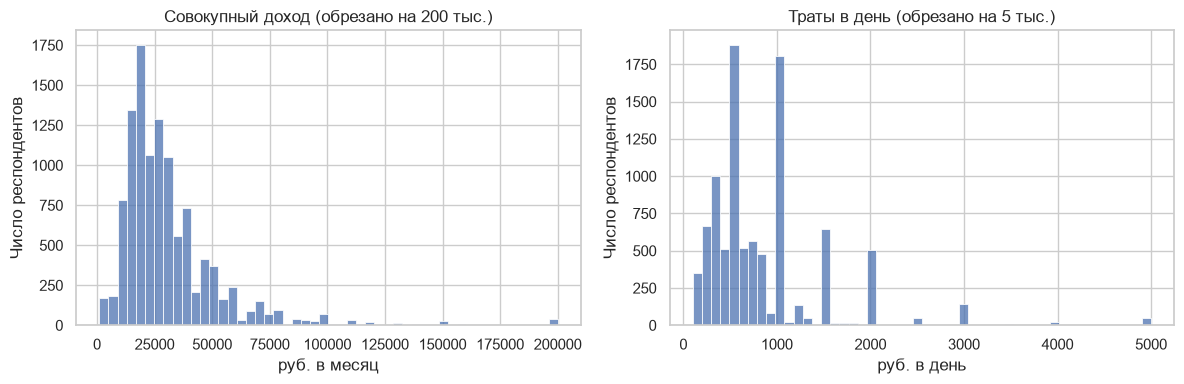

Асимметрия дохода: 10.0 | асимметрия трат: 2.6


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['k66a'].dropna().clip(upper=200000), bins=50, ax=axes[0])
axes[0].set(title='Совокупный доход (обрезано на 200 тыс.)', xlabel='руб. в месяц', ylabel='Число респондентов')
sns.histplot(df['pp10_1'].dropna().clip(upper=5000), bins=50, ax=axes[1])
axes[1].set(title='Траты в день (обрезано на 5 тыс.)', xlabel='руб. в день', ylabel='Число респондентов')
plt.tight_layout()
plt.show()
print('Асимметрия дохода:', round(df['k66a'].skew(), 1), '| асимметрия трат:', round(df['pp10_1'].skew(), 1))

**Вывод по описательной статистике**

- Выборка смещена к старшему возрасту: 39,1% — 56 лет и старше, 18–25 лет — 9,3%. 46% имеют среднее общее образование и ниже, 73,5% живут в городах.
- Большинство декларирует сберегательные установки: регулярно откладывают деньги 55,1% («пожалуй» + «точно про меня»), держат запас на непредвиденные расходы 68%. Вклад есть у 73,6%.
- К покупкам в кредит 48,2% относятся плохо, хорошо — 17,7%. Активный кредит есть у 6,9%, акции — у 1,2%.
- Учёт доходов и расходов не ведут 87,7%. Свою финансовую грамотность оценивают как хорошую или отличную 11%.
- Доход и траты распределены с сильной правосторонней асимметрией (коэффициенты 10,0 и 2,6). Для них, помимо Пирсона, используем Спирмена.

## 8. Возраст

**Гипотезы для таблиц сопряжённости:**
- H0: финансовое поведение не зависит от возрастной группы (распределения ответов во всех группах одинаковы);
- H1: финансовое поведение связано с возрастной группой.

**Гипотезы для коэффициентов корреляции:**
- H0: коэффициент корреляции в генеральной совокупности равен 0;
- H1: коэффициент отличен от 0.

### 8.1 Таблицы сопряжённости и хи-квадрат

In [37]:
for t in ['y6_2', 'y6_3', 'p6', 'y9', 'credit']:
    crosstab_chi2('gr_vozr', t, 'Возраст')

**Возрастная группа × Регулярно откладываю**, % по строкам

y6_2,Точно не про меня,Скорее не про меня,"Пожалуй, про меня",Точно про меня,n
gr_vozr,,,,,
18-25 лет,21.5,41.4,28.1,9.0,1099
26-35 лет,11.3,37.2,38.2,13.4,1903
36-45 лет,10.8,37.8,36.5,14.9,2173
46-55 лет,11.3,33.1,40.9,14.7,2111
56 лет и старше,8.5,29.2,42.7,19.6,4660


χ² = 338.6, df = 12, p = 3.53e-65, V Крамера = 0.097 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


**Возрастная группа × Держу запас на непредвиденное**, % по строкам

y6_3,Точно не про меня,Скорее не про меня,"Пожалуй, про меня",Точно про меня,n
gr_vozr,,,,,
18-25 лет,16.8,32.5,36.0,14.7,1103
26-35 лет,8.7,25.3,47.5,18.5,1900
36-45 лет,7.7,26.0,47.0,19.4,2181
46-55 лет,8.5,24.1,47.7,19.8,2117
56 лет и старше,6.2,19.8,49.9,24.1,4670


...

y9,Плохо,"В чем-то хорошо, а в чем-то плохо",Хорошо,n
gr_vozr,,,,
18-25 лет,36.2,38.0,25.8,1022
26-35 лет,37.3,42.3,20.4,1838
36-45 лет,38.6,40.6,20.8,2128
46-55 лет,43.4,35.6,21.0,2068
56 лет и старше,62.1,26.2,11.6,4500


χ² = 620.6, df = 8, p = 8.92e-129, V Крамера = 0.164 (слабая); ячеек с ожидаемой частотой < 5: 0%


**Возрастная группа × Есть кредит**, % по строкам

credit,Нет,Да,n
gr_vozr,,,
18-25 лет,97.1,2.9,1132
26-35 лет,91.1,8.9,1930
36-45 лет,89.9,10.1,2204
46-55 лет,90.9,9.1,2146
56 лет и старше,95.3,4.7,4750


χ² = 127.8, df = 4, p = 1.14e-26, V Крамера = 0.103 (слабая); ячеек с ожидаемой частотой < 5: 0%


### 8.2 Коэффициенты корреляции

Возрастная группа и порядковые показатели — коэффициент Кендалла.

In [38]:
for t in ['y6_1', 'y6_2', 'y6_3', 'y9', 't12', 't1']:
    corr_test('gr_vozr', t, 'kendall', 'Возраст')

Возрастная группа × Сберегаю на будущее | Кендалл: r = 0.135, p = 3.53e-69, n = 11966 — связь слабая
Возрастная группа × Регулярно откладываю | Кендалл: r = 0.123, p = 2.13e-57, n = 11946 — связь слабая
Возрастная группа × Держу запас на непредвиденное | Кендалл: r = 0.106, p = 1.41e-42, n = 11971 — связь слабая
Возрастная группа × Отношение к кредитам | Кендалл: r = -0.183, p = 1.93e-114, n = 11556 — связь слабая
Возрастная группа × Учёт доходов и расходов | Кендалл: r = 0.003, p = 0.724, n = 11974 — связь практически отсутствует
Возрастная группа × Финансовая грамотность | Кендалл: r = -0.122, p = 1.2e-56, n = 11817 — связь слабая


Возраст в годах и дихотомические показатели — точечно-бисериальный коэффициент.

In [39]:
for t in ['credit', 'p6', 'p1_1a']:
    corr_test('i_h5', t, 'pointbiserial', 'Возраст')

Возраст × Есть кредит | Точечно-бисериальный: r = -0.053, p = 5.34e-09, n = 12162 — связь практически отсутствует
Возраст × Есть вклад | Точечно-бисериальный: r = -0.117, p = 2.13e-38, n = 12162 — связь слабая
Возраст × Есть акции | Точечно-бисериальный: r = -0.002, p = 0.783, n = 12162 — связь практически отсутствует


Возраст и траты — Пирсон и Спирмен (траты сильно асимметричны).

In [40]:
corr_test('i_h5', 'pp10_1', 'pearson', 'Возраст')
corr_test('i_h5', 'pp10_1', 'spearman', 'Возраст')

Возраст × Траты в день | Пирсон: r = -0.095, p = 1.46e-20, n = 9568 — связь практически отсутствует
Возраст × Траты в день | Спирмен: r = -0.083, p = 2.98e-16, n = 9568 — связь практически отсутствует


Строим график долей по возрастным группам (доли среди ответивших).

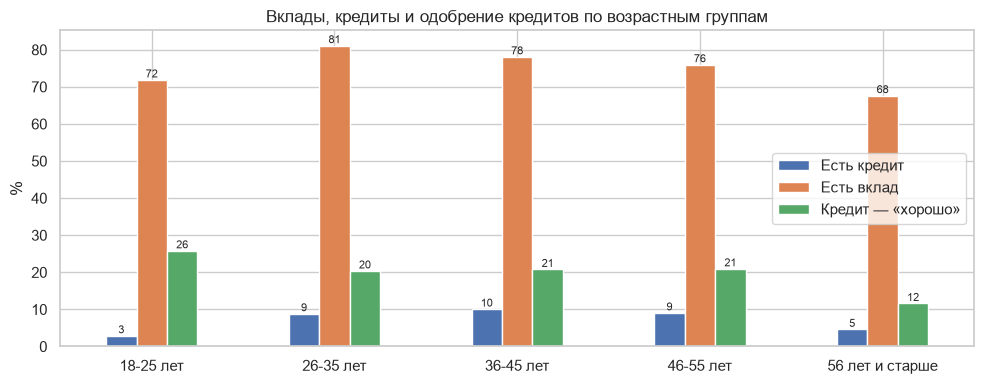

In [41]:
share = (df.groupby('gr_vozr')
           .agg(**{'Есть кредит': ('credit', 'mean'), 'Есть вклад': ('p6', 'mean')})
           .assign(**{'Кредит — «хорошо»': df.assign(g=(df['y9'] == 3).astype(float).where(df['y9'].notna())).groupby('gr_vozr')['g'].mean()})
           .mul(100).rename(index=labels['gr_vozr']))
ax = share.plot(kind='bar', figsize=(10, 4), rot=0)
ax.set_ylabel('%')
ax.set_xlabel('')
ax.set_title('Вклады, кредиты и одобрение кредитов по возрастным группам')
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f', fontsize=8)
plt.tight_layout()
plt.show()

**Вывод по возрасту**

H0 отвергается для сбережений, отношения к кредитам, наличия кредита и вклада (p < 0,001). Связи слабые: V Крамера 0,09–0,16, |τ| до 0,18.

- **Сбережения растут с возрастом.** Регулярно откладывают 37,1% в группе 18–25 лет и 62,3% в группе 56+ (τ = 0,12). Так же ведут себя «сбережения на будущее» (τ = 0,14) и «запас на непредвиденное» (τ = 0,11).
- **Отношение к кредитам ухудшается с возрастом** — самая сильная связь в блоке (V = 0,16, τ = −0,18). Плохо к кредитам относятся 36,2% молодёжи и 62,1% в группе 56+.
- **Кредит и вклад связаны с возрастом нелинейно.** Активный кредит чаще всего у 36–45 лет (10,1%), реже у 18–25 (2,9%) и 56+ (4,7%). Вклады: максимум у 26–35 лет (81,1%), минимум у 56+ (67,7%). Поэтому бисериальные коэффициенты малы (−0,05 и −0,12), а хи-квадрат связь фиксирует: линейный коэффициент недооценивает такую зависимость.
- **Самооценка финансовой грамотности снижается с возрастом** (τ = −0,12).
- **H0 не отвергается** для учёта доходов и расходов (p = 0,72) и наличия акций (p = 0,78). Связь возраста с тратами статистически значима, но практически отсутствует (r = −0,095).

Итог: возраст определяет скорее установки, чем поведение. Старшие больше сберегают и избегают кредитов; кредитная активность сосредоточена в среднем возрасте.

## 9. Уровень образования

**Гипотезы для таблиц сопряжённости:**
- H0: финансовое поведение не зависит от уровня образования;
- H1: финансовое поведение связано с уровнем образования.

**Гипотезы для коэффициентов корреляции:** H0 — коэффициент равен 0; H1 — коэффициент отличен от 0.

### 9.1 Таблицы сопряжённости и хи-квадрат

In [42]:
for t in ['y6_2', 'p6', 'y9', 'credit', 't12', 'p1_1a']:
    crosstab_chi2('gr_educ', t, 'Образование')

**Образование × Регулярно откладываю**, % по строкам

y6_2,Точно не про меня,Скорее не про меня,"Пожалуй, про меня",Точно про меня,n
gr_educ,,,,,
Среднее общее и ниже,13.5,37.5,36.0,12.9,5470
Среднее специальное,9.7,33.3,41.1,15.9,3085
Высшее и неполное высшее,8.2,28.3,42.6,20.8,3372


χ² = 221.1, df = 6, p = 5.96e-45, V Крамера = 0.096 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


**Образование × Есть вклад**, % по строкам

p6,Нет,Да,n
gr_educ,,,
Среднее общее и ниже,37.5,62.5,5584
Среднее специальное,22.0,78.0,3144
Высшее и неполное высшее,12.2,87.8,3412


...

t12,Не ведётся,Неполный,Полный,n
gr_educ,,,,
Среднее общее и ниже,90.8,6.8,2.4,5469
Среднее специальное,87.4,9.3,3.3,3102
Высшее и неполное высшее,82.9,12.6,4.5,3383


χ² = 120.8, df = 4, p = 3.63e-25, V Крамера = 0.071 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


**Образование × Есть акции**, % по строкам

p1_1a,Нет,Да,n
gr_educ,,,
Среднее общее и ниже,99.4,0.6,5584
Среднее специальное,99.2,0.8,3144
Высшее и неполное высшее,97.4,2.6,3412


χ² = 75.2, df = 2, p = 4.66e-17, V Крамера = 0.079 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


### 9.2 Коэффициенты корреляции

Образование (порядковая, 3 градации) и порядковые показатели — Кендалл.

In [43]:
for t in ['y6_1', 'y6_2', 'y6_3', 'y9', 't12', 't1']:
    corr_test('gr_educ', t, 'kendall', 'Образование')

Образование × Сберегаю на будущее | Кендалл: r = 0.118, p = 1.02e-48, n = 11947 — связь слабая
Образование × Регулярно откладываю | Кендалл: r = 0.118, p = 6.93e-49, n = 11927 — связь слабая
Образование × Держу запас на непредвиденное | Кендалл: r = 0.142, p = 1.24e-69, n = 11952 — связь слабая
Образование × Отношение к кредитам | Кендалл: r = 0.031, p = 0.000221, n = 11537 — связь практически отсутствует
Образование × Учёт доходов и расходов | Кендалл: r = 0.093, p = 1.82e-27, n = 11954 — связь практически отсутствует
Образование × Финансовая грамотность | Кендалл: r = 0.257, p = 8.41e-223, n = 11796 — связь слабая


Строим матрицу коэффициентов Кендалла.

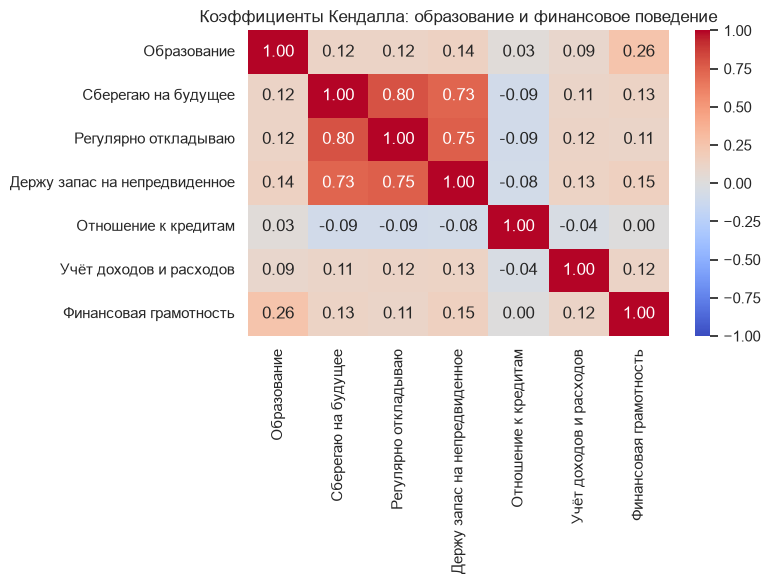

In [44]:
cols = ['gr_educ', 'y6_1', 'y6_2', 'y6_3', 'y9', 't12', 't1']
matrix = df[cols].corr(method='kendall').rename(index=names, columns=names)
plt.figure(figsize=(8, 6))
sns.heatmap(matrix, vmin=-1, vmax=1, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Коэффициенты Кендалла: образование и финансовое поведение')
plt.tight_layout()
plt.show()

**Вывод по образованию**

H0 отвергается для всех показателей (p < 0,01), но сила связей различается.

- **Вклады — самая сильная связь в блоке** (V = 0,25). Вклад есть у 62,5% со средним общим образованием и у 87,8% с высшим.
- **Самооценка финансовой грамотности растёт с образованием** (τ = 0,26).
- **Сбережения растут с образованием слабо** (τ = 0,12–0,14). Регулярно откладывают 48,9% со средним общим и 63,4% с высшим.
- **Учёт доходов и расходов** ведут 9,2% со средним общим и 17,1% с высшим (V = 0,07). Акции есть у 0,6% и 2,6% (V = 0,08).
- **Кредиты почти не зависят от образования:** отношение к кредитам — V = 0,04, τ = 0,03; наличие кредита — 6,1% против 7,9%, V = 0,03. Значимость здесь — эффект большой выборки, содержательной связи нет.

Итог: образование связано прежде всего с использованием банковских продуктов и уверенностью в финансовых знаниях, слабее — со сбережениями, и не связано с кредитным поведением. Часть эффекта может объясняться тем, что люди с высшим образованием чаще живут в крупных городах (τ = −0,16) и лучше обеспечены (τ = 0,16), см. раздел 12.

## 10. Особенности места проживания

**Гипотезы для таблиц сопряжённости:**
- H0: финансовое поведение не зависит от типа / размера населённого пункта (региона);
- H1: финансовое поведение связано с типом / размером населённого пункта (регионом).

**Гипотезы для коэффициентов корреляции:** H0 — коэффициент равен 0; H1 — коэффициент отличен от 0.

`size` закодирован от Москвы (1) до села (8), поэтому отрицательный коэффициент означает, что показатель растёт с размером населённого пункта.

### 10.1 Таблицы сопряжённости и хи-квадрат

Город / село.

In [45]:
for t in ['y6_2', 'p6', 'y9', 'credit', 't12']:
    crosstab_chi2('sett_typ', t, 'Место проживания')

**Тип н/п × Регулярно откладываю**, % по строкам

y6_2,Точно не про меня,Скорее не про меня,"Пожалуй, про меня",Точно про меня,n
sett_typ,,,,,
Город,10.4,34.6,39.9,15.1,8782
Село,13.0,31.7,37.1,18.1,3164


χ² = 38.1, df = 3, p = 2.74e-08, V Крамера = 0.056 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


**Тип н/п × Есть вклад**, % по строкам

p6,Нет,Да,n
sett_typ,,,
Город,19.1,80.9,8940
Село,46.6,53.4,3222


...

credit,Нет,Да,n
sett_typ,,,
Город,93.1,6.9,8940
Село,93.1,6.9,3222


χ² = 0.0, df = 1, p = 0.946, V Крамера = 0.001 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


**Тип н/п × Учёт доходов и расходов**, % по строкам

t12,Не ведётся,Неполный,Полный,n
sett_typ,,,,
Город,86.8,9.4,3.7,8816
Село,90.0,8.2,1.8,3158


χ² = 32.6, df = 2, p = 8.34e-08, V Крамера = 0.052 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


Размер населённого пункта.

In [46]:
for t in ['y6_2', 'p6', 'credit']:
    crosstab_chi2('size', t, 'Место проживания')

**Размер н/п × Регулярно откладываю**, % по строкам

y6_2,Точно не про меня,Скорее не про меня,"Пожалуй, про меня",Точно про меня,n
size,,,,,
г.Москва,17.4,24.8,34.2,23.5,1095
г.Санкт-Петербург,5.6,25.9,46.4,22.1,375
свыше 1 млн.чел. (кроме столиц),7.0,40.1,37.9,15.0,949
от 500 тыс.чел. до 1 млн.чел.,13.5,34.1,41.6,10.9,1955
от 100 тыс.чел. до 500 тыс.чел.,7.3,37.3,39.8,15.6,1709
от 10 тыс.чел. до 100 тыс.чел.,9.6,37.4,39.2,13.8,2331
менее 10 тыс.чел.,6.5,32.5,48.6,12.4,461
сельские населенные пункты,13.1,31.5,37.1,18.3,3071


χ² = 317.3, df = 21, p = 9.44e-55, V Крамера = 0.094 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


**Размер н/п × Есть вклад**, % по строкам

p6,Нет,Да,n
size,,,
г.Москва,6.5,93.5,1098
г.Санкт-Петербург,6.3,93.7,397
свыше 1 млн.чел. (кроме столиц),18.4,81.6,953
от 500 тыс.чел. до 1 млн.чел.,18.1,81.9,2012
от 100 тыс.чел. до 500 тыс.чел.,18.5,81.5,1736
от 10 тыс.чел. до 100 тыс.чел.,23.7,76.3,2378
менее 10 тыс.чел.,50.0,50.0,462
сельские населенные пункты,46.8,53.2,3126


χ² = 1275.1, df = 7, p = 4.13e-271, V Крамера = 0.324 (умеренная); ячеек с ожидаемой частотой < 5: 0%


**Размер н/п × Есть кредит**, % по строкам

credit,Нет,Да,n
size,,,
г.Москва,93.2,6.8,1098
г.Санкт-Петербург,92.9,7.1,397
свыше 1 млн.чел. (кроме столиц),95.1,4.9,953
от 500 тыс.чел. до 1 млн.чел.,93.0,7.0,2012
от 100 тыс.чел. до 500 тыс.чел.,92.4,7.6,1736
от 10 тыс.чел. до 100 тыс.чел.,91.9,8.1,2378
менее 10 тыс.чел.,97.0,3.0,462
сельские населенные пункты,93.2,6.8,3126


χ² = 23.3, df = 7, p = 0.00151, V Крамера = 0.044 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


Регион (номинальная переменная, только хи-квадрат). Выводим регионы с крайними значениями доли вкладов.

In [47]:
tab = pd.crosstab(df['psu'], df['p6'])
chi2, p, dof, expected = chi2_contingency(tab)
v = association(tab, method='cramer')
print(f'Регион × Есть вклад: χ² = {chi2:.1f}, df = {dof}, p = {p:.3g}, V Крамера = {v:.3f} ({strength(v)})')
results.append({'Фактор': 'Место проживания', 'Переменные': 'Регион × Есть вклад', 'Метод': 'χ² / V Крамера',
                'Коэффициент': round(v, 3), 'p': p, 'Сила связи': strength(v)})

reg = df.groupby('psu')['p6'].mean().mul(100).round(1).rename(index=labels['psu']).sort_values()
pd.concat([reg.head(5), reg.tail(5)]).to_frame('Есть вклад, %')

Регион × Есть вклад: χ² = 2585.4, df = 31, p = 0, V Крамера = 0.461 (умеренная)


,"Есть вклад, %"
psu,
Республика Кабардино-Балкария,4.6
Алтайский край,40.5
Пензенская область,42.8
Калужская область,53.1
Волгоградская область,54.7
Республика Удмуртия,87.2
Московская область,90.9
Томская область,90.9
г. Москва,93.5


### 10.2 Коэффициенты корреляции

Размер населённого пункта и порядковые показатели — Спирмен (8 градаций).

In [48]:
for t in ['y6_1', 'y6_2', 'y6_3', 'y9', 't12', 't1']:
    corr_test('size', t, 'spearman', 'Место проживания')

Размер н/п × Сберегаю на будущее | Спирмен: r = -0.020, p = 0.0257, n = 11966 — связь практически отсутствует
Размер н/п × Регулярно откладываю | Спирмен: r = -0.005, p = 0.573, n = 11946 — связь практически отсутствует
Размер н/п × Держу запас на непредвиденное | Спирмен: r = -0.042, p = 5.47e-06, n = 11971 — связь практически отсутствует
Размер н/п × Отношение к кредитам | Спирмен: r = 0.026, p = 0.0058, n = 11556 — связь практически отсутствует
Размер н/п × Учёт доходов и расходов | Спирмен: r = -0.056, p = 6.21e-10, n = 11974 — связь практически отсутствует
Размер н/п × Финансовая грамотность | Спирмен: r = -0.129, p = 1.08e-44, n = 11817 — связь слабая


Город / село и метрические показатели — точечно-бисериальный коэффициент.

In [49]:
corr_test('pp10_1', 'city', 'pointbiserial', 'Место проживания')
corr_test('k66a', 'city', 'pointbiserial', 'Место проживания')

Траты в день × Город (1) / село (0) | Точечно-бисериальный: r = 0.085, p = 1.01e-16, n = 9568 — связь практически отсутствует
Доход × Город (1) / село (0) | Точечно-бисериальный: r = 0.122, p = 3.85e-38, n = 11138 — связь слабая


Сравниваем средние и медианы трат и дохода в городе и селе.

In [50]:
(df.groupby('sett_typ')[['pp10_1', 'k66a']]
   .agg(['mean', 'median']).round(0)
   .rename(index=labels['sett_typ']))

pp10_1            k66a         
           mean median     mean   median
sett_typ                                
Город     859.0  700.0  33683.0  26190.0
Село      723.0  500.0  25602.0  21000.0

Строим график доли регулярно откладывающих и имеющих вклад по размеру населённого пункта.

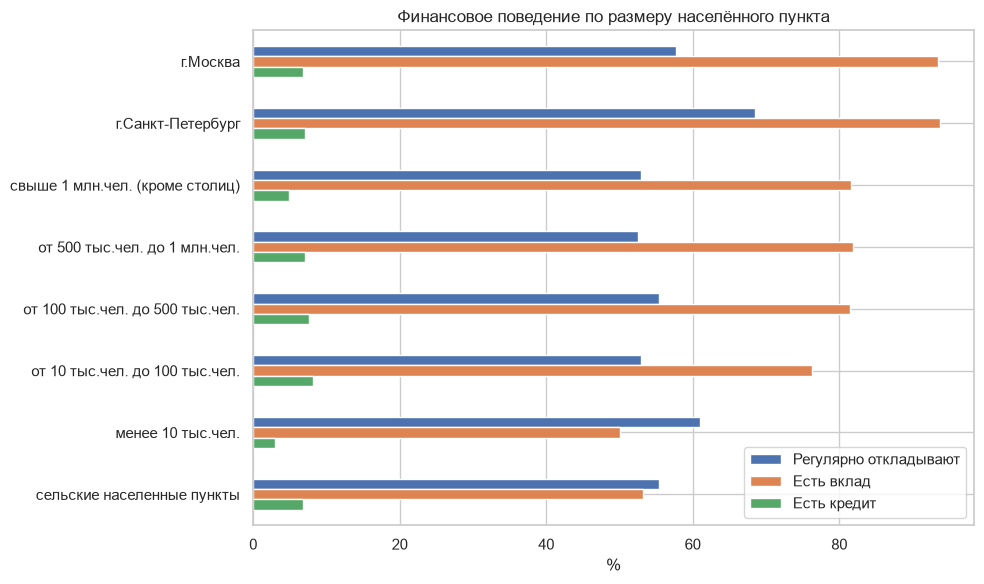

In [51]:
share = pd.DataFrame({
    'Регулярно откладывают': df.assign(g=(df['y6_2'] >= 3).astype(float).where(df['y6_2'].notna())).groupby('size')['g'].mean(),
    'Есть вклад': df.groupby('size')['p6'].mean(),
    'Есть кредит': df.groupby('size')['credit'].mean(),
}).mul(100).rename(index=labels['size'])
ax = share.plot(kind='barh', figsize=(10, 6))
ax.set_xlabel('%')
ax.set_ylabel('')
ax.invert_yaxis()
ax.set_title('Финансовое поведение по размеру населённого пункта')
plt.tight_layout()
plt.show()

**Вывод по месту проживания**

- **Вклады — главное различие.** Вклад есть у 80,9% горожан и 53,4% сельских жителей (V = 0,28). По размеру н/п связь умеренная (V = 0,32): 93,5–93,7% в Москве и Санкт-Петербурге, около 50% в н/п до 10 тыс. и в сёлах. По регионам связь умеренная (V = 0,46): от 4,6% в Кабардино-Балкарии до 93,7% в Санкт-Петербурге.
- **Наличие кредита от типа н/п не зависит:** 6,9% и в городе, и в селе, χ² = 0,0, p = 0,95 — H0 не отвергается. По размеру н/п связь практически отсутствует (V = 0,04).
- **Сберегательные установки почти не связаны с местом проживания:** город/село — V = 0,06; размер н/п и «регулярно откладываю» — ρ = −0,005, p = 0,57, H0 не отвергается.
- **Финансовая грамотность выше в крупных н/п** (ρ = −0,13; шкала размера обратная). Учёт доходов и расходов и отношение к кредитам почти не связаны с местом проживания (|ρ| ≤ 0,06, V ≤ 0,07).
- **Доход и траты в городе выше:** медианный доход 26 190 против 21 000 руб. (r_pb = 0,12), медианные траты 700 против 500 руб. в день (r_pb = 0,09).

Итог: место проживания влияет на доступ к банковским продуктам и уровень доходов, а не на склонность сберегать или брать кредиты. Сильная региональная дифференциация по вкладам указывает на неравномерное развитие банковской инфраструктуры.

## 11. Социальное положение

Социальное положение измеряется тремя переменными: социальная группа (номинальная), материальное положение (порядковая), доход (метрическая).

**Гипотезы для таблиц сопряжённости:**
- H0: финансовое поведение не зависит от социальной группы;
- H1: финансовое поведение связано с социальной группой.

**Гипотезы для коэффициентов корреляции:** H0 — коэффициент равен 0; H1 — коэффициент отличен от 0.

### 11.1 Таблицы сопряжённости и хи-квадрат

In [52]:
for t in ['y6_2', 'p6', 'y9', 'credit', 't12']:
    crosstab_chi2('soc_group', t, 'Социальное положение')

**Социальная группа × Регулярно откладываю**, % по строкам

y6_2,Точно не про меня,Скорее не про меня,"Пожалуй, про меня",Точно про меня,n
soc_group,,,,,
Руководители и предприниматели,8.6,29.0,45.1,17.3,711
Специалисты высшей квалификации,6.9,26.8,44.3,22.0,1232
Специалисты средней квалификации и служащие,9.0,36.0,39.6,15.5,1823
Рабочие и работники сферы услуг,11.2,40.6,36.8,11.4,2465
Неквалифицированные работники,14.4,38.6,36.7,10.4,472
Не работают: пенсионеры,9.8,30.0,41.2,19.0,3594
Не работают: не пенсионеры,20.1,36.4,31.2,12.4,1554


χ² = 386.9, df = 18, p = 4.86e-71, V Крамера = 0.104 (слабая); ячеек с ожидаемой частотой < 5: 0%


**Социальная группа × Есть вклад**, % по строкам

p6,Нет,Да,n
soc_group,,,
Руководители и предприниматели,10.4,89.6,719
Специалисты высшей квалификации,8.0,92.0,1247
Специалисты средней квалификации и служащие,9.7,90.3,1850
Рабочие и работники сферы услуг,20.0,80.0,2503
Неквалифицированные работники,23.6,76.4,483
Не работают: пенсионеры,36.8,63.2,3667
Не работают: не пенсионеры,54.2,45.8,1596


...

credit,Нет,Да,n
soc_group,,,
Руководители и предприниматели,87.8,12.2,719
Специалисты высшей квалификации,90.9,9.1,1247
Специалисты средней квалификации и служащие,90.1,9.9,1850
Рабочие и работники сферы услуг,91.0,9.0,2503
Неквалифицированные работники,89.6,10.4,483
Не работают: пенсионеры,96.6,3.4,3667
Не работают: не пенсионеры,96.9,3.1,1596


χ² = 198.6, df = 6, p = 3.72e-40, V Крамера = 0.128 (слабая); ячеек с ожидаемой частотой < 5: 0%


**Социальная группа × Учёт доходов и расходов**, % по строкам

t12,Не ведётся,Неполный,Полный,n
soc_group,,,,
Руководители и предприниматели,82.2,14.2,3.6,713
Специалисты высшей квалификации,83.4,12.7,4.0,1238
Специалисты средней квалификации и служащие,87.2,9.2,3.6,1825
Рабочие и работники сферы услуг,90.3,7.8,1.9,2465
Неквалифицированные работники,90.0,7.5,2.5,481
Не работают: пенсионеры,88.3,7.9,3.9,3610
Не работают: не пенсионеры,87.9,9.3,2.8,1550


χ² = 81.3, df = 12, p = 2.3e-12, V Крамера = 0.059 (практически отсутствует); ячеек с ожидаемой частотой < 5: 0%


Строим тепловую карту долей по социальным группам.

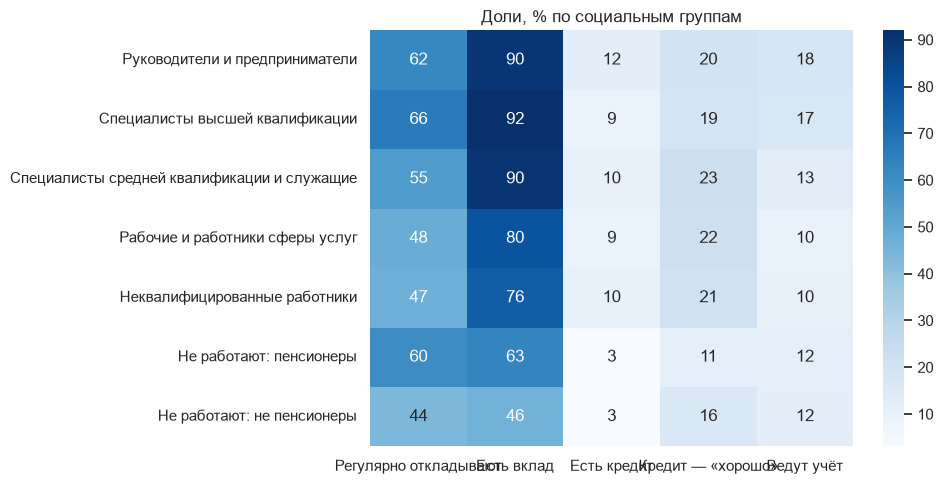

In [53]:
heat = pd.DataFrame({
    'Регулярно откладывают': df.assign(g=(df['y6_2'] >= 3).astype(float).where(df['y6_2'].notna())).groupby('soc_group', observed=True)['g'].mean(),
    'Есть вклад': df.groupby('soc_group', observed=True)['p6'].mean(),
    'Есть кредит': df.groupby('soc_group', observed=True)['credit'].mean(),
    'Кредит — «хорошо»': df.assign(g=(df['y9'] == 3).astype(float).where(df['y9'].notna())).groupby('soc_group', observed=True)['g'].mean(),
    'Ведут учёт': df.assign(g=(df['t12'] >= 2).astype(float).where(df['t12'].notna())).groupby('soc_group', observed=True)['g'].mean(),
}).mul(100)
plt.figure(figsize=(10, 5))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='Blues')
plt.title('Доли, % по социальным группам')
plt.ylabel('')
plt.tight_layout()
plt.show()

### 11.2 Коэффициенты корреляции

Материальное положение (порядковая, 6 градаций) и порядковые показатели — Спирмен.

In [54]:
for t in ['y6_1', 'y6_2', 'y6_3', 'y9', 't12', 't1']:
    corr_test('k85', t, 'spearman', 'Социальное положение')

Материальное положение × Сберегаю на будущее | Спирмен: r = 0.224, p = 4.98e-132, n = 11590 — связь слабая
Материальное положение × Регулярно откладываю | Спирмен: r = 0.242, p = 1.29e-153, n = 11578 — связь слабая
Материальное положение × Держу запас на непредвиденное | Спирмен: r = 0.244, p = 5.98e-157, n = 11598 — связь слабая
Материальное положение × Отношение к кредитам | Спирмен: r = 0.075, p = 1.42e-15, n = 11231 — связь практически отсутствует
Материальное положение × Учёт доходов и расходов | Спирмен: r = 0.076, p = 2.23e-16, n = 11617 — связь практически отсутствует
Материальное положение × Финансовая грамотность | Спирмен: r = 0.208, p = 4.2e-112, n = 11443 — связь слабая


Доход и дихотомические показатели — точечно-бисериальный коэффициент.

In [55]:
for t in ['p6', 'credit', 'p1_1a']:
    corr_test('k66a', t, 'pointbiserial', 'Социальное положение')

Доход × Есть вклад | Точечно-бисериальный: r = 0.159, p = 4.84e-64, n = 11138 — связь слабая
Доход × Есть кредит | Точечно-бисериальный: r = 0.082, p = 2.81e-18, n = 11138 — связь практически отсутствует
Доход × Есть акции | Точечно-бисериальный: r = 0.101, p = 1.27e-26, n = 11138 — связь слабая


Доход и траты — Пирсон и Спирмен.

In [56]:
corr_test('k66a', 'pp10_1', 'pearson', 'Социальное положение')
corr_test('k66a', 'pp10_1', 'spearman', 'Социальное положение')

Доход × Траты в день | Пирсон: r = 0.284, p = 1.55e-165, n = 8920 — связь слабая
Доход × Траты в день | Спирмен: r = 0.359, p = 8.06e-270, n = 8920 — связь умеренная


Строим диаграмму рассеяния дохода и трат (логарифмические оси).

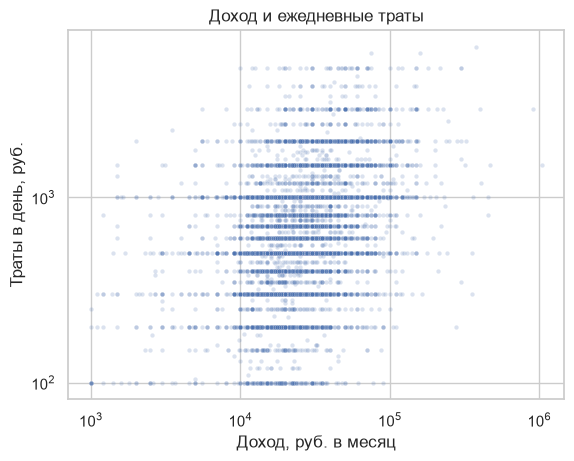

In [57]:
vals = df[['k66a', 'pp10_1']].dropna()
vals = vals[(vals['k66a'] > 0) & (vals['pp10_1'] > 0)]
ax = sns.scatterplot(data=vals, x='k66a', y='pp10_1', alpha=0.2, s=10)
ax.set(xscale='log', yscale='log', xlabel='Доход, руб. в месяц', ylabel='Траты в день, руб.')
plt.title('Доход и ежедневные траты')
plt.show()

**Вывод по социальному положению**

H0 отвергается для всех показателей социальной группы (p < 0,001). Социальное положение даёт самые сильные связи из четырёх факторов.

- **Вклады** (V = 0,35, умеренная связь). Вклад есть у 92% специалистов высшей квалификации, 89,6% руководителей и предпринимателей, 80% рабочих, 63,2% неработающих пенсионеров и 45,8% неработающих непенсионеров.
- **Регулярные сбережения** (V = 0,10). Чаще всего откладывают специалисты высшей квалификации (66,3%), руководители (62,4%) и пенсионеры (60,2%). Реже всего — неработающие непенсионеры (43,6%), неквалифицированные работники (47,1%) и рабочие (48,2%).
- **Кредиты.** Активный кредит есть у 12,2% руководителей и около 3% неработающих (V = 0,13). Пенсионеры чаще всех относятся к кредитам плохо — 64,9% (V = 0,17).
- **Учёт доходов и расходов** с группой почти не связан (V = 0,06).
- **Материальное положение** слабо положительно связано со сбережениями (ρ = 0,22–0,24) и самооценкой грамотности (ρ = 0,21). С отношением к кредитам и учётом связь практически отсутствует (ρ < 0,08).
- **Доход** слабо связан с наличием вклада (r_pb = 0,16) и акций (r_pb = 0,10), с кредитом — практически не связан (r_pb = 0,08). С тратами связь слабая по Пирсону (r = 0,28) и умеренная по Спирмену (ρ = 0,36). Из-за асимметрии дохода корректнее Спирмен.

Итог: финансовое поведение определяется прежде всего наличием работы и квалификацией. Занятые специалисты и руководители чаще пользуются вкладами и кредитами и регулярно сберегают; неработающие непенсионеры — наиболее уязвимая группа по всем показателям.

## 12. Сводная таблица результатов

Собираем все тесты в одну таблицу. Решение по H0 принимаем при α = 0,05.

In [58]:
summary = pd.DataFrame(results)
summary['Решение'] = np.where(summary['p'] < 0.05, 'H0 отвергается', 'H0 не отвергается')
summary['p'] = summary['p'].map(lambda x: f'{x:.3g}')
pd.set_option('display.max_rows', 200)
summary

,Фактор,Переменные,Метод,Коэффициент,p,Сила связи,Решение
0,Возраст,Возрастная группа × Регулярно откладываю,χ² / V Крамера,0.097,3.53e-65,практически отсутствует,H0 отвергается
1,Возраст,Возрастная группа × Держу запас на непредвиденное,χ² / V Крамера,0.089,1.56e-53,практически отсутствует,H0 отвергается
2,Возраст,Возрастная группа × Есть вклад,χ² / V Крамера,0.120,1.6e-36,слабая,H0 отвергается
3,Возраст,Возрастная группа × Отношение к кредитам,χ² / V Крамера,0.164,8.92e-129,слабая,H0 отвергается
4,Возраст,Возрастная группа × Есть кредит,χ² / V Крамера,0.103,1.14e-26,слабая,H0 отвергается
5,Возраст,Возрастная группа × Сберегаю на будущее,Кендалл,0.135,3.53e-69,слабая,H0 отвергается
6,Возраст,Возрастная группа × Регулярно откладываю,Кендалл,0.123,2.13e-57,слабая,H0 отвергается
7,Возраст,Возрастная группа × Держу запас на непредвиденное,Кендалл,0.106,1.41e-42,слабая,H0 отвергается
8,Возраст,Возрастная группа × Отношение к кредитам,Кендалл,-0.183,1.93e-114,слабая,H0 отвергается
9,Возраст,Возрастная группа × Учёт доходов и расходов,Кендалл,0.003,0.724,практически отсутствует,H0 не отвергается


Сравниваем силу связи по факторам: максимальный модуль коэффициента в каждом блоке.

In [59]:
(pd.DataFrame(results)
   .assign(abs_coef=lambda d: d['Коэффициент'].abs())
   .groupby('Фактор')['abs_coef'].agg(['max', 'mean']).round(3)
   .sort_values('max', ascending=False)
   .rename(columns={'max': 'Максимум |r| / V', 'mean': 'Среднее |r| / V'}))

,Максимум |r| / V,Среднее |r| / V
Фактор,,
Место проживания,0.461,0.109
Социальное положение,0.359,0.179
Образование,0.257,0.110
Возраст,0.183,0.100


Проверяем связь факторов между собой (возможное смешение эффектов) — Кендалл.

In [60]:
cols = ['gr_vozr', 'gr_educ', 'size', 'k85']
df[cols].corr(method='kendall').rename(index=names, columns=names).round(3)

,Возрастная группа,Образование,Размер н/п,Материальное положение
Возрастная группа,1.000,-0.055,0.058,-0.083
Образование,-0.055,1.000,-0.156,0.159
Размер н/п,0.058,-0.156,1.000,0.006
Материальное положение,-0.083,0.159,0.006,1.000


## 13. Итоговые выводы

1. **Все четыре фактора статистически связаны с финансовым поведением**, но связи в основном слабые. При n ≈ 12 тыс. почти любые различия значимы, поэтому выводы делаются по силе связи (V Крамера, коэффициенты корреляции), а не по p-value.
2. **Социальное положение — самый сильный фактор.** Наиболее выраженная связь — с наличием вклада (V = 0,35); связь с регулярными сбережениями и кредитами слабая. Наиболее уязвимы неработающие непенсионеры.
3. **Место проживания** связано прежде всего с вкладами. Связь с размером населённого пункта умеренная (V = 0,32), с регионом — тоже умеренная (V = 0,46). На склонность сберегать и брать кредиты место проживания практически не влияет; доля заёмщиков в городе и селе одинакова (H0 не отвергается).
4. **Образование** слабо связано с вкладами (V = 0,25), самооценкой финансовой грамотности (τ = 0,26) и сбережениями. С кредитным поведением связи практически нет.
5. **Возраст** слабо определяет установки: старшие чаще сберегают и хуже относятся к кредитам (τ = −0,18). Кредитная активность и вклады связаны с возрастом нелинейно, с пиком в 26–45 лет. Поэтому для возраста хи-квадрат информативнее линейного коэффициента.
6. **H0 не отвергнута** для пар: возраст × учёт доходов и расходов, возраст × наличие акций, город/село × наличие кредита, размер н/п × регулярные сбережения.

**Ограничения**
- Корреляционный анализ не устанавливает причинность. «Влияние» здесь означает статистическую связь.
- Факторы связаны между собой: образование — с размером н/п (τ = −0,16) и материальным положением (τ = 0,16); возраст — с пенсионным статусом. Попарный анализ не разделяет их эффекты.
- Кодировка `c4` по метке противоречит данным; переменная перекодирована по содержательным признакам (раздел 5). Доля вкладов (73,6%) высока, переменная `p6` может включать и другие банковские сбережения.
- В массиве нет весов, результаты отражают невзвешенную выборку 32 регионов.